In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/mistu1801/cod-project-data/TrainDataset/TrainDataset/Edge/COD10K-CAM-1-Aquatic-2-ClownFish-12.png
/kaggle/input/datasets/mistu1801/cod-project-data/TrainDataset/TrainDataset/Edge/COD10K-CAM-2-Terrestrial-38-Lizard-2293.png
/kaggle/input/datasets/mistu1801/cod-project-data/TrainDataset/TrainDataset/Edge/COD10K-CAM-1-Aquatic-13-Pipefish-758.png
/kaggle/input/datasets/mistu1801/cod-project-data/TrainDataset/TrainDataset/Edge/COD10K-CAM-2-Terrestrial-38-Lizard-2327.png
/kaggle/input/datasets/mistu1801/cod-project-data/TrainDataset/TrainDataset/Edge/COD10K-CAM-2-Terrestrial-23-Cat-1397.png
/kaggle/input/datasets/mistu1801/cod-project-data/TrainDataset/TrainDataset/Edge/COD10K-CAM-1-Aquatic-14-ScorpionFish-949.png
/kaggle/input/datasets/mistu1801/cod-project-data/TrainDataset/TrainDataset/Edge/COD10K-CAM-2-Terrestrial-42-Sciuridae-2415.png
/kaggle/input/datasets/mistu1801/cod-project-data/TrainDataset/TrainDataset/Edge/COD10K-CAM-4-Amphibian-68-Toad-4992.png
/kaggle/in

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import cv2
import timm
import random
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from glob import glob
from tqdm import tqdm


In [3]:
class CODDataset(Dataset):
    def __init__(self, img_paths, mask_paths, size=448, augment=False):
        self.img_paths  = img_paths
        self.mask_paths = mask_paths
        self.size       = size
        self.augment    = augment
 
        self.img_norm = transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
        self.color_jitter = transforms.ColorJitter(
            brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05
        )
 
    def __len__(self):
        return len(self.img_paths)
 
    def __getitem__(self, idx):
        img  = cv2.cvtColor(cv2.imread(self.img_paths[idx]),  cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.mask_paths[idx], 0)
 
        
        img  = cv2.resize(img,  (self.size, self.size), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (self.size, self.size), interpolation=cv2.INTER_NEAREST)
 
        if self.augment:
            # horizontal flip
            if random.random() > 0.5:
                img  = np.fliplr(img).copy()
                mask = np.fliplr(mask).copy()
 
            # vertical flip
            if random.random() > 0.5:
                img  = np.flipud(img).copy()
                mask = np.flipud(mask).copy()
 
            # random crop-and-resize (scale 0.75 – 1.0)
            if random.random() > 0.5:
                s   = random.uniform(0.75, 1.0)
                h_s = int(self.size * s)
                w_s = int(self.size * s)
                y0  = random.randint(0, self.size - h_s)
                x0  = random.randint(0, self.size - w_s)
                img  = cv2.resize(img[y0:y0+h_s, x0:x0+w_s, :],
                                  (self.size, self.size), interpolation=cv2.INTER_LINEAR)
                mask = cv2.resize(mask[y0:y0+h_s, x0:x0+w_s],
                                  (self.size, self.size), interpolation=cv2.INTER_NEAREST)
 
        # tensors
        img  = torch.from_numpy(img.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).float().unsqueeze(0) / 255.0
        mask = (mask > 0.5).float()
 
        if self.augment:
            img = self.color_jitter(img)
 
        img = self.img_norm(img)
        return img, mask
 
 
def load_paths(base_path):
    imgs  = sorted(glob(base_path + "/Imgs/*"))
    masks = sorted(glob(base_path + "/GT/*"))
    return imgs, masks
 
 
BASE = "/kaggle/input/datasets/mistu1801/cod-project-data/"
 
train_imgs,   train_masks   = load_paths(BASE + "TrainDataset/TrainDataset/")
camo_imgs,    camo_masks    = load_paths(BASE + "TestDataset/TestDataset/CAMO")
cham_imgs,    cham_masks    = load_paths(BASE + "TestDataset/TestDataset/CHAMELEON")
codtest_imgs, codtest_masks = load_paths(BASE + "TestDataset/TestDataset/COD10K")
 
test_imgs  = camo_imgs  + cham_imgs  + codtest_imgs
test_masks = camo_masks + cham_masks + codtest_masks
 
full_dataset = CODDataset(train_imgs, train_masks, augment=False)
train_size   = int(0.85 * len(full_dataset))
val_size     = len(full_dataset) - train_size
train_indices, val_indices = random_split(
    range(len(full_dataset)), [train_size, val_size]
)
 
train_dataset = CODDataset(
    [train_imgs[i]  for i in train_indices],
    [train_masks[i] for i in train_indices],
    augment=True
)
val_dataset = CODDataset(
    [train_imgs[i]  for i in val_indices],
    [train_masks[i] for i in val_indices],
    augment=False
)
 
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=4, shuffle=False, num_workers=2, pin_memory=True)
 
test_dataset = CODDataset(test_imgs, test_masks, augment=False)
test_loader  = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)
 

In [4]:
class CBAM(nn.Module):
    def __init__(self, in_c):
        super().__init__()
        self.ca = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_c, in_c // 8, 1),
            nn.ReLU(),
            nn.Conv2d(in_c // 8, in_c, 1),
            nn.Sigmoid()
        )
        self.sa = nn.Sequential(
            nn.Conv2d(2, 1, 7, padding=3),
            nn.Sigmoid()
        )
 
    def forward(self, x):
        x   = x * self.ca(x)
        avg = torch.mean(x, dim=1, keepdim=True)
        mx  = torch.max(x,  dim=1, keepdim=True)[0]
        x   = x * self.sa(torch.cat([avg, mx], dim=1))
        return x
 

In [5]:
class FAM(nn.Module):
    
    def __init__(self, high_c, low_c, out_c):
        super().__init__()
        self.conv_high = nn.Conv2d(high_c, out_c, 1)
        self.conv_low  = nn.Conv2d(low_c,  out_c, 1)
        self.conv = nn.Sequential(
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU()
        )
 
    def forward(self, x_high, x_low):
        x_high = F.interpolate(x_high, size=x_low.shape[2:],
                               mode='bilinear', align_corners=False)
        return self.conv(self.conv_high(x_high) + self.conv_low(x_low))


In [6]:
class SAM(nn.Module):
    
    def __init__(self, in_c, out_c):
        super().__init__()
        mid = out_c // 4
        self.b1 = nn.Sequential(nn.Conv2d(in_c, mid, 1), nn.BatchNorm2d(mid), nn.ReLU())
        self.b2 = nn.Sequential(nn.Conv2d(in_c, mid, 3, padding=2,  dilation=2),  nn.BatchNorm2d(mid), nn.ReLU())
        self.b3 = nn.Sequential(nn.Conv2d(in_c, mid, 3, padding=4,  dilation=4),  nn.BatchNorm2d(mid), nn.ReLU())
        self.b4 = nn.Sequential(nn.Conv2d(in_c, mid, 3, padding=8,  dilation=8),  nn.BatchNorm2d(mid), nn.ReLU())
        self.fuse = nn.Sequential(
            nn.Conv2d(out_c, out_c, 1),
            nn.BatchNorm2d(out_c),
            nn.ReLU()
        )
 
    def forward(self, x):
        return self.fuse(torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1))


In [7]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU()
        )
        self.attn = CBAM(out_c)
 
    def forward(self, x):
        return self.attn(self.conv(x))

In [8]:
class CODNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model(
            'convnext_small', pretrained=True, features_only=True
        )
        ch = self.backbone.feature_info.channels()  # [96, 192, 384, 768]
 
        self.sam4 = SAM(ch[3], 256)
 
        self.fam4 = FAM(256,  ch[2], 256)
        self.fam3 = FAM(128,  ch[1], 128)
        self.fam2 = FAM(64,   ch[0], 64)
 
        self.up4 = ConvBlock(256,  256)
        self.up3 = ConvBlock(256,  128)
        self.up2 = ConvBlock(128,  64)
        self.up1 = ConvBlock(64,   32)
 
        self.final     = nn.Conv2d(32,  1, 1)
        self.edge_head = nn.Conv2d(32,  1, 1)
 
        # deep supervision heads
        self.ds3 = nn.Conv2d(128, 1, 1)
        self.ds4 = nn.Conv2d(256, 1, 1)
 
    def forward(self, x):
        f1, f2, f3, f4 = self.backbone(x)
 
        d4 = self.up4(self.sam4(f4))            # 768 → SAM → 256
        d3 = self.up3(self.fam4(d4, f3))
        d2 = self.up2(self.fam3(d3, f2))
        d1 = self.up1(self.fam2(d2, f1))
 
        out  = self.final(d1)
        edge = self.edge_head(d1)
 
        # deep supervision (only used during training)
        out3 = self.ds4(d4)
        out4 = self.ds3(d3)
 
        return out, edge, out3, out4

In [9]:
bce = nn.BCEWithLogitsLoss()
 
 
def weighted_bce(pred, gt):
    weight = 1 + 5 * torch.abs(F.avg_pool2d(gt, 31, 1, 15) - gt)
    loss   = F.binary_cross_entropy_with_logits(pred, gt, reduction='none')
    return (weight * loss).mean()
 
 
def dice_loss(pred, gt):
    smooth = 1e-5
    inter  = (pred * gt).sum()
    return 1 - (2 * inter + smooth) / (pred.sum() + gt.sum() + smooth)
 
 
def iou_loss(pred, gt):
    inter = (pred * gt).sum()
    union = (pred + gt).sum()
    return 1 - (inter + 1) / (union - inter + 1)
 
 
def lovasz_hinge(pred, gt):
    
    signs  = 2.0 * gt - 1.0                     # +1 / -1
    errors = 1.0 - pred * signs
    errors_sorted, perm = torch.sort(errors, dim=0, descending=True)
    gt_sorted = gt[perm]
    gt_sum    = gt_sorted.sum()
    inter     = gt_sum - gt_sorted.cumsum(0)
    union     = gt_sum + (1 - gt_sorted).cumsum(0)
    jaccard   = 1.0 - inter / union.clamp(min=1)
    grad      = jaccard[1:] - jaccard[:-1]
    grad      = torch.cat([jaccard[:1], grad])
    return torch.dot(F.relu(errors_sorted), grad)
 
 
def loss_fn(pred, edge_pred, out3, out4, gt):
    # ── up-sample all preds to gt size ──────────────────────
    def up(t):
        return F.interpolate(t, size=gt.shape[2:], mode='bilinear', align_corners=False)
 
    pred      = up(pred)
    edge_pred = up(edge_pred)
    out3      = up(out3)
    out4      = up(out4)
 
    pred_sig  = torch.sigmoid(pred).clamp(1e-4, 1 - 1e-4)
    flat_sig  = pred_sig.view(-1)
    flat_gt   = gt.view(-1)
 
    # ── main loss ────────────────────────────────────────────
    main = (
        weighted_bce(pred, gt)
        + dice_loss(pred_sig, gt)
        + iou_loss(pred_sig, gt)
        + 0.5 * lovasz_hinge(flat_sig, flat_gt)   # ← Lovász
    )
 
    # ── edge loss ────────────────────────────────────────────
    edge_gt   = F.conv2d(gt, torch.ones(1, 1, 3, 3).to(gt.device), padding=1)
    edge_gt   = (edge_gt > 0).float() - gt
    edge_loss = bce(edge_pred, edge_gt) + dice_loss(torch.sigmoid(edge_pred), edge_gt)
 
    # ── deep supervision ─────────────────────────────────────
    ds_loss = (
        weighted_bce(out3, gt) + dice_loss(torch.sigmoid(out3).clamp(1e-4, 1-1e-4), gt)
        + weighted_bce(out4, gt) + dice_loss(torch.sigmoid(out4).clamp(1e-4, 1-1e-4), gt)
    ) * 0.4
 
    return main + 1.0 * edge_loss + ds_loss

In [10]:
device    = "cuda" if torch.cuda.is_available() else "cpu"
model     = CODNet().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
 
# Cosine-annealing LR with warm restarts — prevents loss plateaus
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6
)
 
NUM_EPOCHS = 50   # completes a full 3rd cosine annealing cycle
 
best_val_loss = float('inf')
 
for epoch in range(NUM_EPOCHS):
    # ── train ────────────────────────────────────────────────
    model.train()
    total_loss = 0.0
    for imgs, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [train]"):
        imgs, masks = imgs.to(device), masks.to(device)
        preds, edge, out3, out4 = model(imgs)
        loss = loss_fn(preds, edge, out3, out4, masks)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)  # stability
        optimizer.step()
        total_loss += loss.item()
 
    scheduler.step()
 
    # ── validation ───────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            preds, edge, out3, out4 = model(imgs)
            val_loss += loss_fn(preds, edge, out3, out4, masks).item()
 
    val_loss /= len(val_loader)
    lr_now    = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1:3d}  "
          f"train={total_loss/len(train_loader):.4f}  "
          f"val={val_loss:.4f}  lr={lr_now:.2e}")
 
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print("  ↑ saved best model")
 
# Load best checkpoint for evaluation
model.load_state_dict(torch.load("best_model.pth"))


model.safetensors:   0%|          | 0.00/201M [00:00<?, ?B/s]

Epoch 1/50 [train]: 100%|██████████| 859/859 [08:08<00:00,  1.76it/s]


Epoch   1  train=5.0167  val=4.2135  lr=9.76e-05
  ↑ saved best model


Epoch 2/50 [train]: 100%|██████████| 859/859 [08:02<00:00,  1.78it/s]


Epoch   2  train=3.9296  val=3.6298  lr=9.05e-05
  ↑ saved best model


...

Epoch 49/50 [train]: 100%|██████████| 859/859 [08:00<00:00,  1.79it/s]


Epoch  49  train=1.5501  val=2.7392  lr=5.44e-05


Epoch 50/50 [train]: 100%|██████████| 859/859 [08:09<00:00,  1.76it/s]


Epoch  50  train=1.5329  val=2.6982  lr=5.05e-05


<All keys matched successfully>

In [11]:
def predict_tta(model, imgs, device):
   
    with torch.no_grad():
        p0, *_ = model(imgs)
        p1, *_ = model(torch.flip(imgs, dims=[3]))   # h-flip
        p1     = torch.flip(p1, dims=[3])             # un-flip
        p2, *_ = model(torch.flip(imgs, dims=[2]))   # v-flip
        p2     = torch.flip(p2, dims=[2])             # un-flip
        return torch.sigmoid((p0 + p1 + p2) / 3.0)
 
 
def adaptive_threshold(p_np):
   
    p_u8 = (p_np * 255).astype(np.uint8)
    thresh, binary = cv2.threshold(p_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    foreground_ratio = binary.mean() / 255.0
    if foreground_ratio < 0.005 or foreground_ratio > 0.98:
        # Otsu failed — use fixed threshold
        binary = (p_u8 > int(0.35 * 255)).astype(np.uint8) * 255
    kernel = np.ones((5, 5), np.uint8)
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  kernel)
    return binary
 
 
model.eval()
mae_list, f_list, e_list, s_list = [], [], [], []
 
with torch.no_grad():
    for imgs, masks in tqdm(test_loader, desc="Evaluating"):
        imgs, masks = imgs.to(device), masks.to(device)
 
        preds = predict_tta(model, imgs, device)
        preds = F.interpolate(preds, size=masks.shape[2:], mode='bilinear', align_corners=False)
 
        for i in range(preds.shape[0]):
            p_np = preds[i].cpu().numpy().squeeze()
            p_np = (p_np - p_np.min()) / (p_np.max() - p_np.min() + 1e-8)
 
            binary  = adaptive_threshold(p_np)
            p_final = torch.tensor(binary / 255.0).to(device).float()
            g       = masks[i]
 
            # MAE
            mae_list.append(torch.mean(torch.abs(p_final - g)).item())
 
            # F-beta  (β² = 0.3 is standard for COD)
            p_flat = p_final.view(-1)
            g_flat = g.view(-1)
            tp        = (p_flat * g_flat).sum()
            precision = tp / (p_flat.sum() + 1e-8)
            recall    = tp / (g_flat.sum() + 1e-8)
            f_score   = ((1 + 0.3**2) * precision * recall /
                         (0.3**2 * precision + recall + 1e-8)).item()
            f_list.append(f_score)
 
            # E-measure (Enhanced alignment measure)
            mu_p = p_flat.mean()
            mu_g = g_flat.mean()
            align = (2 * (p_flat - mu_p) * (g_flat - mu_g)) / (
                (p_flat - mu_p)**2 + (g_flat - mu_g)**2 + 1e-8
            )
            e_list.append((((align + 1)**2) / 4).mean().item())
 
            # S-measure (proper region-aware version)
            # object region
            alpha = 0.5
            fg    = g_flat.mean()
            if fg > 1e-4:
                x_o = (p_flat * g_flat).sum() / (g_flat.sum() + 1e-8)
                y_o = g_flat.mean()
                s_o = 2 * x_o / (x_o**2 + 1 + 1e-8)
            else:
                s_o = torch.tensor(0.0).to(device)
            # background region
            bg     = 1 - g_flat
            bg_sum = bg.sum() + 1e-8
            if (1 - fg) > 1e-4:
                x_b = ((1 - p_flat) * bg).sum() / bg_sum
                y_b = bg.mean()
                s_b = 2 * x_b / (x_b**2 + 1 + 1e-8)
            else:
                s_b = torch.tensor(0.0).to(device)
            s_list.append((alpha * s_o + (1 - alpha) * s_b).item())
 
print("\n===== FINAL RESULTS (Notebook 13 Upgrade) =====")
print("MAE:      ", np.mean(mae_list))
print("F_beta:   ", np.mean(f_list))
print("E_measure:", np.mean(e_list))
print("S_measure:", np.mean(s_list))

Evaluating: 100%|██████████| 588/588 [04:26<00:00,  2.20it/s]


===== FINAL RESULTS (Notebook 13 Upgrade) =====
MAE:       0.030034526566151992
F_beta:    0.8071047994317153
E_measure: 0.9177454132586718
S_measure: 0.9565816364523505


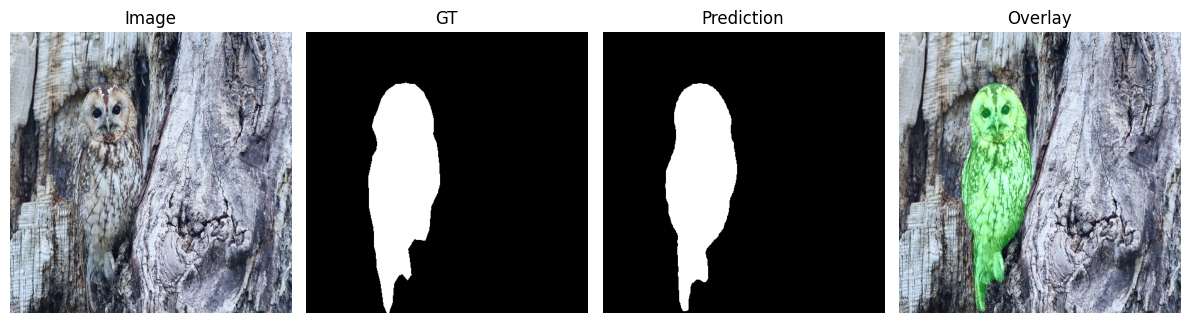

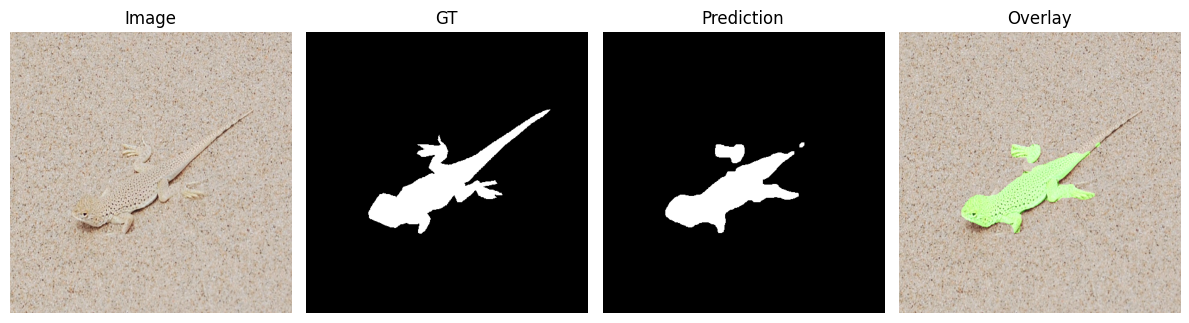

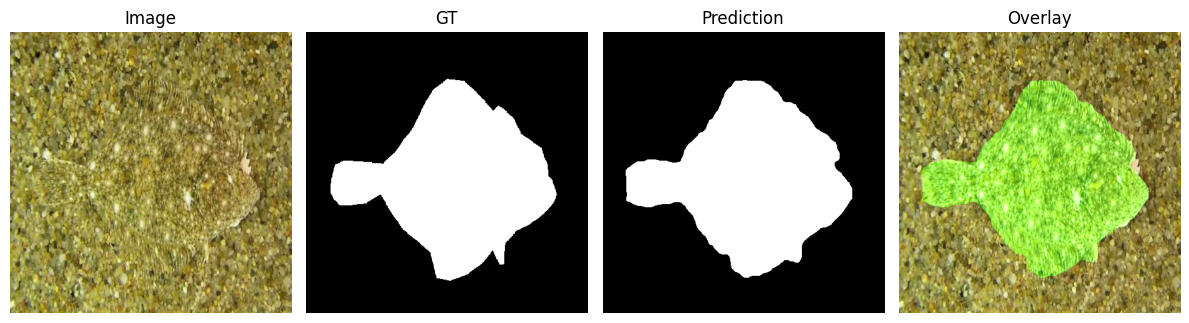

In [12]:
def visualize(model, loader, device, n=3):
    model.eval()
    imgs, masks = next(iter(loader))
    idx   = torch.randperm(imgs.size(0))[:n]
    imgs  = imgs[idx].to(device)
    masks = masks[idx]
 
    preds = predict_tta(model, imgs, device)
    preds = F.interpolate(preds, size=masks.shape[2:], mode='bilinear', align_corners=False)
 
    imgs  = imgs.cpu()
    preds = preds.cpu()
 
    for i in range(n):
        plt.figure(figsize=(12, 4))
 
        img = imgs[i].permute(1, 2, 0).numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)
 
        gt   = masks[i][0].numpy()
        p_np = preds[i][0].numpy()
        p_np = (p_np - p_np.min()) / (p_np.max() - p_np.min() + 1e-8)
 
        binary = adaptive_threshold(p_np)
 
        # soft overlay for visual debugging
        overlay = img.copy()
        pred_mask = (binary > 127).astype(np.float32)
        overlay[:, :, 1] = np.clip(overlay[:, :, 1] + 0.35 * pred_mask, 0, 1)  # green tint
 
        plt.subplot(1, 4, 1); plt.imshow(img);            plt.title("Image");      plt.axis("off")
        plt.subplot(1, 4, 2); plt.imshow(gt, cmap='gray'); plt.title("GT");         plt.axis("off")
        plt.subplot(1, 4, 3); plt.imshow(binary, cmap='gray'); plt.title("Prediction"); plt.axis("off")
        plt.subplot(1, 4, 4); plt.imshow(overlay);         plt.title("Overlay");    plt.axis("off")
 
        plt.tight_layout()
        plt.show()
 
 
visualize(model, test_loader, device)


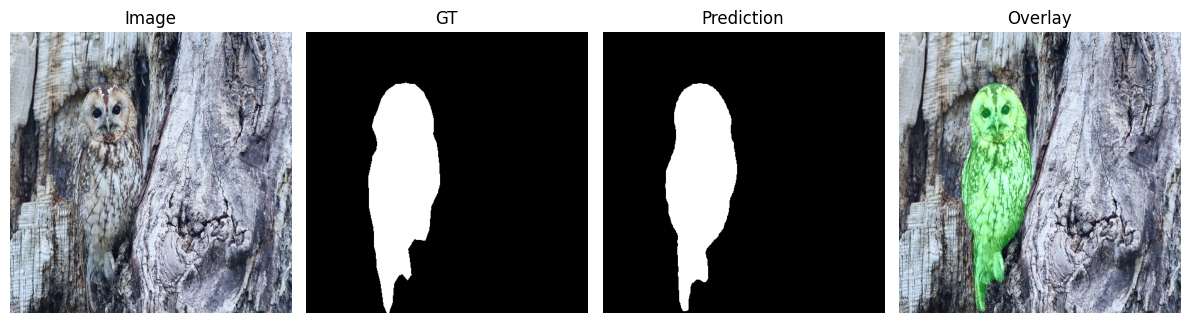

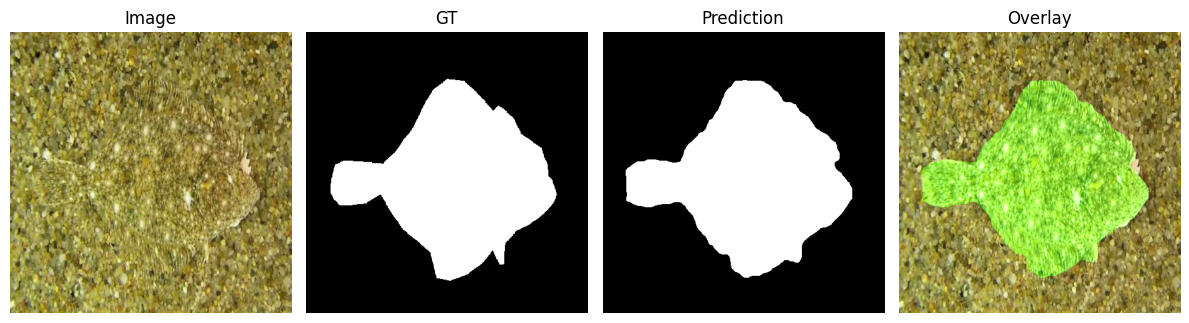

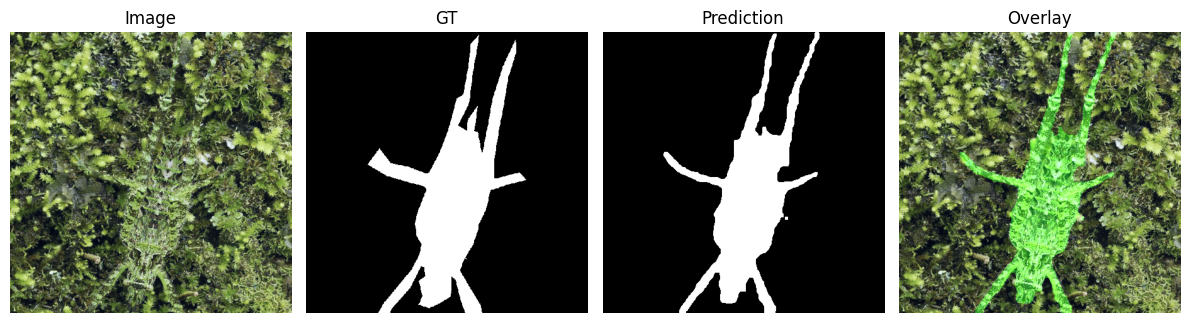

In [13]:
def visualize(model, loader, device, n=3):
    model.eval()
    imgs, masks = next(iter(loader))
    idx   = torch.randperm(imgs.size(0))[:n]
    imgs  = imgs[idx].to(device)
    masks = masks[idx]
 
    preds = predict_tta(model, imgs, device)
    preds = F.interpolate(preds, size=masks.shape[2:], mode='bilinear', align_corners=False)
 
    imgs  = imgs.cpu()
    preds = preds.cpu()
 
    for i in range(n):
        plt.figure(figsize=(12, 4))
 
        img = imgs[i].permute(1, 2, 0).numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)
 
        gt   = masks[i][0].numpy()
        p_np = preds[i][0].numpy()
        p_np = (p_np - p_np.min()) / (p_np.max() - p_np.min() + 1e-8)
 
        binary = adaptive_threshold(p_np)
 
        # soft overlay for visual debugging
        overlay = img.copy()
        pred_mask = (binary > 127).astype(np.float32)
        overlay[:, :, 1] = np.clip(overlay[:, :, 1] + 0.35 * pred_mask, 0, 1)  # green tint
 
        plt.subplot(1, 4, 1); plt.imshow(img);            plt.title("Image");      plt.axis("off")
        plt.subplot(1, 4, 2); plt.imshow(gt, cmap='gray'); plt.title("GT");         plt.axis("off")
        plt.subplot(1, 4, 3); plt.imshow(binary, cmap='gray'); plt.title("Prediction"); plt.axis("off")
        plt.subplot(1, 4, 4); plt.imshow(overlay);         plt.title("Overlay");    plt.axis("off")
 
        plt.tight_layout()
        plt.show()
 
 
visualize(model, test_loader, device)


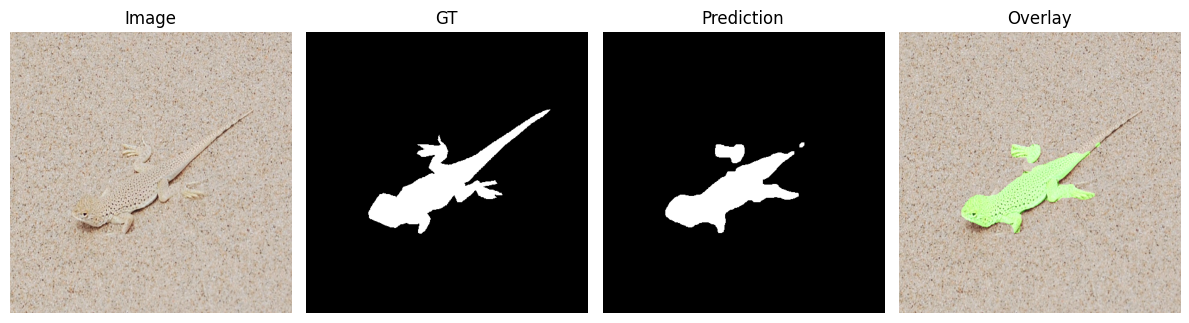

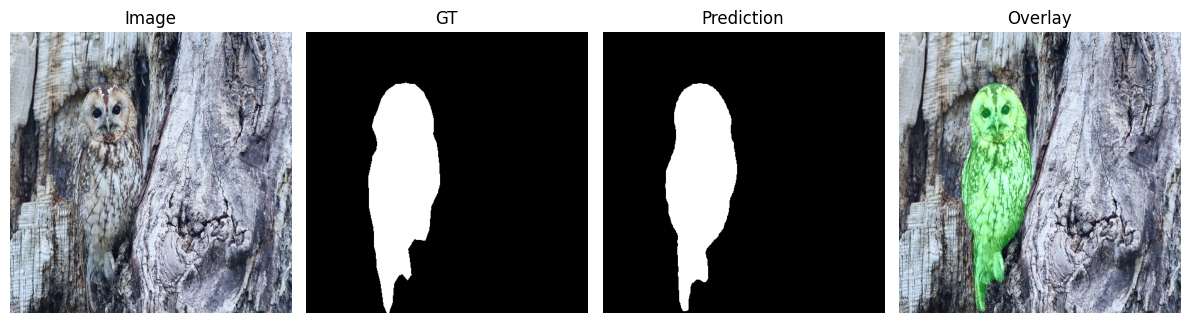

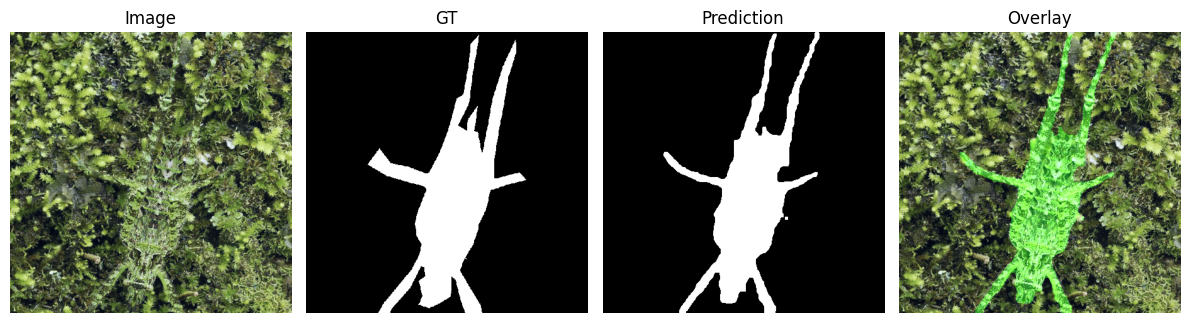

In [14]:
def visualize(model, loader, device, n=3):
    model.eval()
    imgs, masks = next(iter(loader))
    idx   = torch.randperm(imgs.size(0))[:n]
    imgs  = imgs[idx].to(device)
    masks = masks[idx]
 
    preds = predict_tta(model, imgs, device)
    preds = F.interpolate(preds, size=masks.shape[2:], mode='bilinear', align_corners=False)
 
    imgs  = imgs.cpu()
    preds = preds.cpu()
 
    for i in range(n):
        plt.figure(figsize=(12, 4))
 
        img = imgs[i].permute(1, 2, 0).numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)
 
        gt   = masks[i][0].numpy()
        p_np = preds[i][0].numpy()
        p_np = (p_np - p_np.min()) / (p_np.max() - p_np.min() + 1e-8)
 
        binary = adaptive_threshold(p_np)
 
        # soft overlay for visual debugging
        overlay = img.copy()
        pred_mask = (binary > 127).astype(np.float32)
        overlay[:, :, 1] = np.clip(overlay[:, :, 1] + 0.35 * pred_mask, 0, 1)  # green tint
 
        plt.subplot(1, 4, 1); plt.imshow(img);            plt.title("Image");      plt.axis("off")
        plt.subplot(1, 4, 2); plt.imshow(gt, cmap='gray'); plt.title("GT");         plt.axis("off")
        plt.subplot(1, 4, 3); plt.imshow(binary, cmap='gray'); plt.title("Prediction"); plt.axis("off")
        plt.subplot(1, 4, 4); plt.imshow(overlay);         plt.title("Overlay");    plt.axis("off")
 
        plt.tight_layout()
        plt.show()
 
 
visualize(model, test_loader, device)


In [15]:
from torchsummary import summary
import sys

# ─────────────────────────────────────────────────────────────
# MODEL ARCHITECTURE
# ─────────────────────────────────────────────────────────────

save_path = "/kaggle/working/model_architecture.txt"
arch_str  = str(model)

old_stdout = sys.stdout
sys.stdout = open(save_path, "w")

print("=" * 60)
print("FULL MODEL ARCHITECTURE")
print("=" * 60)
print(arch_str)

print("\n" + "=" * 60)
print("LAYER-WISE SUMMARY")
print("=" * 60)
try:
    summary(model, input_size=(3, 448, 448), device=device)
except Exception as e:
    print(f"Summary error: {e}")

print("\n" + "=" * 60)
print("PARAMETER COUNT")
print("=" * 60)
total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen    = total - trainable
print(f"Total parameters     : {total:,}")
print(f"Trainable parameters : {trainable:,}")
print(f"Frozen parameters    : {frozen:,}")
print(f"Model size (approx)  : {total * 4 / 1024**2:.1f} MB")

sys.stdout.close()
sys.stdout = old_stdout

# print to screen as well
with open(save_path, "r") as f:
    print(f.read())

print(f"\n✅ Saved to {save_path}")

FULL MODEL ARCHITECTURE
CODNet(
  (backbone): FeatureListNet(
    (stem_0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (stem_1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    (stages_0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=

In [16]:
import torch
import os

# ─────────────────────────────────────────────────────────────
# SAVE MODEL WEIGHTS
# ─────────────────────────────────────────────────────────────

save_path = "/kaggle/working/codnet_weights.pth"

# option A — saves only weights (recommended, smaller file)
torch.save(model.state_dict(), save_path)

# option B — saves full model including architecture
# torch.save(model, save_path)   # uncomment if you prefer this

size_mb = os.path.getsize(save_path) / 1024**2
print(f"✅ Weights saved to: {save_path}")
print(f"   File size: {size_mb:.1f} MB")

# ─────────────────────────────────────────────────────────────
# VERIFY WEIGHTS LOAD CORRECTLY
# ─────────────────────────────────────────────────────────────

test_model = CODNet().to(device)
test_model.load_state_dict(torch.load(save_path, map_location=device))
test_model.eval()
print("✅ Weights verified — loaded back successfully")

# ─────────────────────────────────────────────────────────────
# ALSO SAVE BEST MODEL IF IT EXISTS
# ─────────────────────────────────────────────────────────────

if os.path.exists("best_model.pth"):
    best_save = "/kaggle/working/codnet_best_weights.pth"
    shutil.copy("best_model.pth", best_save)
    size_mb2 = os.path.getsize(best_save) / 1024**2
    print(f"✅ Best model weights saved to: {best_save}")
    print(f"   File size: {size_mb2:.1f} MB")
else:
    print("⚠️  best_model.pth not found — training may not have completed yet")

✅ Weights saved to: /kaggle/working/codnet_weights.pth
   File size: 205.0 MB


✅ Weights verified — loaded back successfully


NameError: name 'shutil' is not defined

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from glob import glob

# ─────────────────────────────────────────────────────────────
# DATASET INSPECTOR
# ─────────────────────────────────────────────────────────────

BASE = "/kaggle/input/datasets/mistu1801/cod-project-data/"

datasets = {
    "Train": {
        "imgs":  sorted(glob(BASE + "TrainDataset/TrainDataset/Imgs/*")),
        "masks": sorted(glob(BASE + "TrainDataset/TrainDataset/GT/*"))
    },
    "Test - CAMO": {
        "imgs":  sorted(glob(BASE + "TestDataset/TestDataset/CAMO/Imgs/*")),
        "masks": sorted(glob(BASE + "TestDataset/TestDataset/CAMO/GT/*"))
    },
    "Test - CHAMELEON": {
        "imgs":  sorted(glob(BASE + "TestDataset/TestDataset/CHAMELEON/Imgs/*")),
        "masks": sorted(glob(BASE + "TestDataset/TestDataset/CHAMELEON/GT/*"))
    },
    "Test - COD10K": {
        "imgs":  sorted(glob(BASE + "TestDataset/TestDataset/COD10K/Imgs/*")),
        "masks": sorted(glob(BASE + "TestDataset/TestDataset/COD10K/GT/*"))
    },
}

# ─────────────────────────────────────────────────────────────
# 1. SUMMARY TABLE
# ─────────────────────────────────────────────────────────────

print("=" * 55)
print(f"{'Dataset':<22} {'Images':>8} {'Masks':>8} {'Match':>8}")
print("=" * 55)
for name, d in datasets.items():
    match = " yes" if len(d["imgs"]) == len(d["masks"]) else " no"
    print(f"{name:<22} {len(d['imgs']):>8} {len(d['masks']):>8} {match:>8}")
print("=" * 55)
print(f"{'Total Test':<22} {sum(len(d['imgs']) for k,d in datasets.items() if k != 'Train'):>8}")
print()

# ─────────────────────────────────────────────────────────────
# 2. IMAGE SIZE DISTRIBUTION (first 50 images of each dataset)
# ─────────────────────────────────────────────────────────────

print("Image size samples (W x H):")
print("-" * 55)
for name, d in datasets.items():
    sizes = set()
    for p in d["imgs"][:50]:
        img = cv2.imread(p)
        if img is not None:
            h, w = img.shape[:2]
            sizes.add(f"{w}x{h}")
    print(f"  {name:<22}: {', '.join(sorted(sizes))}")
print()

# ─────────────────────────────────────────────────────────────
# 3. VISUALISE 4 SAMPLES FROM EACH DATASET
# ─────────────────────────────────────────────────────────────

for name, d in datasets.items():
    imgs  = d["imgs"]
    masks = d["masks"]
    n     = min(4, len(imgs))

    # pick 4 evenly spaced samples so you see variety
    indices = [int(i * len(imgs) / n) for i in range(n)]

    fig, axes = plt.subplots(n, 2, figsize=(6, n * 3))
    fig.suptitle(f"{name}  ({len(imgs)} images)", fontsize=13, fontweight='bold')

    for row, idx in enumerate(indices):
        img  = cv2.cvtColor(cv2.imread(imgs[idx]),  cv2.COLOR_BGR2RGB)
        mask = cv2.imread(masks[idx], 0)

        fname = os.path.basename(imgs[idx])

        axes[row, 0].imshow(img)
        axes[row, 0].set_title(f"Image: {fname}", fontsize=8)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(mask, cmap='gray')
        axes[row, 1].set_title(f"Mask — fg: {(mask > 127).mean()*100:.1f}%", fontsize=8)
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()
    print()

# ─────────────────────────────────────────────────────────────
# 4. FOREGROUND RATIO STATS (how camouflaged are objects on avg)
# ─────────────────────────────────────────────────────────────

print("Foreground coverage stats (lower = more camouflaged):")
print("-" * 55)
for name, d in datasets.items():
    ratios = []
    for p in d["masks"][:200]:   # sample 200 masks max for speed
        m = cv2.imread(p, 0)
        if m is not None:
            ratios.append((m > 127).mean())
    if ratios:
        print(f"  {name:<22}  mean={np.mean(ratios)*100:.1f}%  "
              f"min={np.min(ratios)*100:.1f}%  max={np.max(ratios)*100:.1f}%")

In [ ]:
import os

# ─────────────────────────────────────────────────────────────
# DATASET IMAGE COUNTER
# ─────────────────────────────────────────────────────────────

train_imgs, train_masks = load_paths(BASE + "TrainDataset/TrainDataset/")
camo_imgs,    camo_masks    = load_paths(BASE + "TestDataset/TestDataset/CAMO")
cham_imgs,    cham_masks    = load_paths(BASE + "TestDataset/TestDataset/CHAMELEON")
codtest_imgs, codtest_masks = load_paths(BASE + "TestDataset/TestDataset/COD10K")

test_imgs  = camo_imgs  + cham_imgs  + codtest_imgs
test_masks = camo_masks + cham_masks + codtest_masks

# ─────────────────────────────────────────────────────────────
# COUNTS
# ─────────────────────────────────────────────────────────────

print("=" * 50)
print(f"{'DATASET BREAKDOWN':^50}")
print("=" * 50)

print(f"\n TRAINING")
print(f"  {'TrainDataset':<25} {len(train_imgs):>6} images")

print(f"\n TESTING")
print(f"  {'CAMO':<25} {len(camo_imgs):>6} images")
print(f"  {'CHAMELEON':<25} {len(cham_imgs):>6} images")
print(f"  {'COD10K':<25} {len(codtest_imgs):>6} images")

print("\n" + "-" * 50)
print(f"  {'Total Test':<25} {len(test_imgs):>6} images")
print(f"  {'Total Train':<25} {len(train_imgs):>6} images")
print("=" * 50)
print(f"  {'GRAND TOTAL':<25} {len(train_imgs) + len(test_imgs):>6} images")
print("=" * 50)

# ─────────────────────────────────────────────────────────────
# TRAIN / VAL SPLIT BREAKDOWN
# ─────────────────────────────────────────────────────────────

train_split = int(0.85 * len(train_imgs))
val_split   = len(train_imgs) - train_split

print(f"\n TRAIN / VAL SPLIT (85% / 15%)")
print("-" * 50)
print(f"  {'Used for training':<25} {train_split:>6} images")
print(f"  {'Used for validation':<25} {val_split:>6} images")
print("=" * 50)






In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from tqdm import tqdm

# ─────────────────────────────────────────────────────────────
# METRIC FUNCTIONS
# ─────────────────────────────────────────────────────────────

def calc_mae(pred, gt):
    return torch.mean(torch.abs(pred - gt)).item()

def calc_fbeta(pred, gt, beta_sq=0.3):
    p_flat = pred.view(-1)
    g_flat = gt.view(-1)
    tp        = (p_flat * g_flat).sum()
    precision = tp / (p_flat.sum() + 1e-8)
    recall    = tp / (g_flat.sum() + 1e-8)
    return ((1 + beta_sq) * precision * recall /
            (beta_sq * precision + recall + 1e-8)).item()

def calc_fw(pred, gt):
    """
    Weighted F-measure — weights errors by distance to boundary.
    Standard metric in COD papers.
    """
    p_flat = pred.view(-1)
    g_flat = gt.view(-1)

    # compute boundary weight map from GT
    gt_np  = gt.squeeze().cpu().numpy().astype(np.uint8)
    kernel = np.ones((5, 5), np.uint8)
    boundary = cv2.dilate(gt_np, kernel) - cv2.erode(gt_np, kernel)
    weight   = torch.tensor(
        cv2.distanceTransform(1 - boundary, cv2.DIST_L2, 5) + 1.0
    ).to(pred.device).view(-1)

    tp_w  = (weight * p_flat * g_flat).sum()
    fp_w  = (weight * p_flat * (1 - g_flat)).sum()
    fn_w  = (weight * (1 - p_flat) * g_flat).sum()

    prec_w = tp_w / (tp_w + fp_w + 1e-8)
    rec_w  = tp_w / (tp_w + fn_w  + 1e-8)
    beta_sq = 1.0
    return ((1 + beta_sq) * prec_w * rec_w /
            (beta_sq * prec_w + rec_w + 1e-8)).item()

def calc_dice(pred, gt):
    p = pred.view(-1)
    g = gt.view(-1)
    return (2 * (p * g).sum() / (p.sum() + g.sum() + 1e-8)).item()

def calc_precision_recall(pred, gt):
    p_flat = pred.view(-1)
    g_flat = gt.view(-1)
    tp        = (p_flat * g_flat).sum()
    precision = (tp / (p_flat.sum() + 1e-8)).item()
    recall    = (tp / (g_flat.sum() + 1e-8)).item()
    return precision, recall

def calc_emeasure(pred, gt):
    p_flat = pred.view(-1)
    g_flat = gt.view(-1)
    mu_p   = p_flat.mean()
    mu_g   = g_flat.mean()
    align  = (2 * (p_flat - mu_p) * (g_flat - mu_g)) / (
        (p_flat - mu_p)**2 + (g_flat - mu_g)**2 + 1e-8
    )
    return (((align + 1)**2) / 4).mean().item()

def calc_smeasure(pred, gt):
    alpha  = 0.5
    p_flat = pred.view(-1)
    g_flat = gt.view(-1)
    fg     = g_flat.mean()
    if fg > 1e-4:
        x_o = (p_flat * g_flat).sum() / (g_flat.sum() + 1e-8)
        s_o = 2 * x_o / (x_o**2 + 1 + 1e-8)
    else:
        s_o = torch.tensor(0.0).to(pred.device)
    bg     = 1 - g_flat
    if (1 - fg) > 1e-4:
        x_b = ((1 - p_flat) * bg).sum() / (bg.sum() + 1e-8)
        s_b = 2 * x_b / (x_b**2 + 1 + 1e-8)
    else:
        s_b = torch.tensor(0.0).to(pred.device)
    return (alpha * s_o + (1 - alpha) * s_b).item()

def calc_biou(pred, gt):
    """Boundary IoU — measures mask quality specifically at edges."""
    pred_np = (pred.squeeze().cpu().numpy() * 255).astype(np.uint8)
    gt_np   = (gt.squeeze().cpu().numpy()   * 255).astype(np.uint8)
    kernel  = np.ones((5, 5), np.uint8)

    pred_boundary = cv2.dilate(pred_np, kernel) - cv2.erode(pred_np, kernel)
    gt_boundary   = cv2.dilate(gt_np,   kernel) - cv2.erode(gt_np,   kernel)

    pred_b = (pred_boundary > 0).astype(np.float32)
    gt_b   = (gt_boundary   > 0).astype(np.float32)

    inter  = (pred_b * gt_b).sum()
    union  = np.clip(pred_b + gt_b, 0, 1).sum()
    return (inter / (union + 1e-8))

# ─────────────────────────────────────────────────────────────
# PER-DATASET EVALUATION
# ─────────────────────────────────────────────────────────────

def evaluate_dataset(model, imgs_list, masks_list, name, device):
    dataset    = CODDataset(imgs_list, masks_list, augment=False)
    loader     = DataLoader(dataset, batch_size=4, shuffle=False, num_workers=2)

    mae_l, fb_l, fw_l, dice_l = [], [], [], []
    prec_l, rec_l, em_l, sm_l, biou_l = [], [], [], [], []

    model.eval()
    with torch.no_grad():
        for imgs, masks in tqdm(loader, desc=f"Evaluating {name}"):
            imgs, masks = imgs.to(device), masks.to(device)
            preds = predict_tta(model, imgs, device)
            preds = F.interpolate(preds, size=masks.shape[2:],
                                  mode='bilinear', align_corners=False)

            for i in range(preds.shape[0]):
                p_np = preds[i].cpu().numpy().squeeze()
                p_np = (p_np - p_np.min()) / (p_np.max() - p_np.min() + 1e-8)

                binary = adaptive_threshold(p_np)
                p      = torch.tensor(binary / 255.0).to(device).float().unsqueeze(0).unsqueeze(0)
                g      = masks[i].unsqueeze(0)

                mae_l.append(calc_mae(p, g))
                fb_l.append(calc_fbeta(p, g))
                fw_l.append(calc_fw(p, g))
                dice_l.append(calc_dice(p, g))
                pr, rc = calc_precision_recall(p, g)
                prec_l.append(pr)
                rec_l.append(rc)
                em_l.append(calc_emeasure(p, g))
                sm_l.append(calc_smeasure(p, g))
                biou_l.append(calc_biou(p, g))

    print(f"\n{'=' * 55}")
    print(f"  {name}")
    print(f"{'=' * 55}")
    print(f"  {'MAE':<25} {np.mean(mae_l):.4f}  (lower is better)")
    print(f"  {'F-beta (β²=0.3)':<25} {np.mean(fb_l):.4f}  (higher is better)")
    print(f"  {'Weighted F-measure':<25} {np.mean(fw_l):.4f}  (higher is better)")
    print(f"  {'Dice / F1':<25} {np.mean(dice_l):.4f}  (higher is better)")
    print(f"  {'Precision':<25} {np.mean(prec_l):.4f}  (higher is better)")
    print(f"  {'Recall':<25} {np.mean(rec_l):.4f}  (higher is better)")
    print(f"  {'E-measure':<25} {np.mean(em_l):.4f}  (higher is better)")
    print(f"  {'S-measure':<25} {np.mean(sm_l):.4f}  (higher is better)")
    print(f"  {'Boundary IoU':<25} {np.mean(biou_l):.4f}  (higher is better)")
    print(f"{'=' * 55}")

    return {
        "MAE": np.mean(mae_l), "F_beta": np.mean(fb_l),
        "F_w": np.mean(fw_l),  "Dice":   np.mean(dice_l),
        "Precision": np.mean(prec_l), "Recall": np.mean(rec_l),
        "E_measure": np.mean(em_l),   "S_measure": np.mean(sm_l),
        "BIoU": np.mean(biou_l)
    }

# ─────────────────────────────────────────────────────────────
# RUN EVALUATION ON ALL DATASETS
# ─────────────────────────────────────────────────────────────

results = {}
results["CAMO"]      = evaluate_dataset(model, camo_imgs,    camo_masks,    "CAMO",      device)
results["CHAMELEON"] = evaluate_dataset(model, cham_imgs,    cham_masks,    "CHAMELEON", device)
results["COD10K"]    = evaluate_dataset(model, codtest_imgs, codtest_masks, "COD10K",    device)

# ─────────────────────────────────────────────────────────────
# COMBINED SUMMARY TABLE
# ─────────────────────────────────────────────────────────────

metrics = ["MAE", "F_beta", "F_w", "Dice", "Precision", "Recall", "E_measure", "S_measure", "BIoU"]

print(f"\n{'=' * 75}")
print(f"  {'FULL RESULTS SUMMARY':^73}")
print(f"{'=' * 75}")
print(f"  {'Metric':<20} {'CAMO':>12} {'CHAMELEON':>12} {'COD10K':>12}")
print(f"{'-' * 75}")
for m in metrics:
    print(f"  {m:<20} "
          f"{results['CAMO'][m]:>12.4f} "
          f"{results['CHAMELEON'][m]:>12.4f} "
          f"{results['COD10K'][m]:>12.4f}")
print(f"{'=' * 75}")

In [ ]:
import os
os.makedirs("/kaggle/working", exist_ok=True)
torch.save(model.state_dict(), "/kaggle/working/best_model.pth")
print("Saved to:", "/kaggle/working/best_model.pth")